# Lab L3.4 · Churn early-warning — logistic vs k-NN vs tree vs forest, value-based targeting, and trees for regression
**Horizon Gulf Bank · Project MIZAN** · CAIP AIP-210 · Certified AI Practitioner · Day 3 · ⏱ 60 min · **Level 3 · Complete solution**

Run a fair bake-off of every Day 3 algorithm on 250k customers, control tree depth, turn scores into a retention campaign with gains and expected value, and see what trees do (and cannot do) on a regression problem.

### Scenario
**Horizon Gulf Bank (HGB)** is a fictional UAE retail bank with 250,000 customers. Its Board approved **Project MIZAN** — an AI decisioning platform covering credit, fraud, collateral valuation, cash logistics, customer retention and document automation. You are a junior ML practitioner in the MIZAN squad.

About **12% of customers leave within six months**. The Retail Retention team can call 10% of the base per half-year and offers a fee waiver worth ≈ AED 150 per accepted offer. They ask MIZAN: *who should we call?* You will choose the algorithm on evidence, explain why depth matters for trees, and turn probabilities into a campaign list that maximises **net value**, not accuracy. The Mortgage team then asks a side question: can trees replace the Day 2 linear valuation model?

**Progressive architecture:** combines L1.1 (master), L1.3 (transaction features) and L3.2 (segments). The churn model is upgraded with a neural network in L4.3 and deployed in the Day 5 capstone (L5.3).

### Objectives
- Compare logistic regression, k-NN, a decision tree and a random forest on the *same* split and metrics
- Use a depth sweep (validation curve) to see tree over-fitting and pick the depth
- Read cumulative-gains and lift charts; size a campaign from a contact budget
- Choose targets by **expected value** (probability × value − cost)
- Fit regression trees and forests, and discover why trees cannot extrapolate a trend

In [1]:
# ── Project MIZAN course setup ─ run this cell first ──────────────────────────
from pathlib import Path
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the course root (the folder that contains data/generate_data.py) from wherever this notebook lives
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "generate_data.py").exists())
DATA = ROOT / "data"          # raw synthetic datasets (read-only)
CKPT = ROOT / "checkpoints"   # hand-off artefacts between labs (lets you start any lab fresh)
CKPT.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": .3})
RNG = 42
print("Course root:", ROOT)

Course root: C:\Users\Pushkar\Downloads\CAIP-AIP210-FINANCIAL-SERVICES-TRAINER-PACK\CAIP-AIP210-TopTier-Courseware


## Step 1 · Assemble, guard against leakage, split

**Why this matters.** Three earlier labs contribute features. Before modelling we assert that **leaky** columns (the account-closure date, retention offers made *after* the customer started leaving) and **protected attributes** are not in the feature list, then make a stratified 60/20/20 split so every model is judged on the same validation and test rows.

In [2]:
import json
cust = pd.read_parquet(CKPT / "customers_clean.parquet")                    # L1.1
seg = pd.read_parquet(CKPT / "customer_segments.parquet")                  # L3.2
txf = pd.read_parquet(CKPT / "customer_txn_features.parquet")              # L1.3
TXN = ["has_card_activity", "txn_count", "log_amt_mean", "recency_days", "spend_trend", "ecom_share", "n_mcc"]
df = (cust.merge(seg[["customer_id", "segment"]], on="customer_id", validate="one_to_one")
          .merge(txf[["customer_id"] + TXN], on="customer_id", validate="one_to_one"))
df["log_balance"], df["log_salary"] = np.log1p(df.avg_balance_aed), np.log1p(df.monthly_salary_aed)
NUM = ["age", "tenure_months", "num_products", "salary_transfer", "has_credit_card", "has_personal_loan", "has_auto_loan", "has_mortgage",
       "log_balance", "log_salary", "digital_logins_30d", "branch_visits_90d", "complaints_12m", "days_since_last_txn", "aecb_score"] + TXN
CAT = ["segment", "employment_type", "emirate"]
FORBIDDEN = {"account_closed_date", "retention_offer_made", "gender", "nationality_group"}   # leakage + protected attributes
from sklearn.model_selection import train_test_split
assert not FORBIDDEN & set(NUM + CAT), "leaky or protected column in the feature list!"
tr, rest = train_test_split(df, test_size=0.4, stratify=df.churned_6m, random_state=RNG)
va, te = train_test_split(rest, test_size=0.5, stratify=rest.churned_6m, random_state=RNG)
pd.DataFrame({"rows": [len(tr), len(va), len(te)], "churn_rate": [tr.churned_6m.mean(), va.churned_6m.mean(), te.churned_6m.mean()]},
             index=["train", "valid", "test"]).round(4)

,rows,churn_rate
train,150000,0.1198
valid,50000,0.1198
test,50000,0.1197


> **Think like a practitioner.** Why is `days_since_last_txn` fine as a feature but `account_closed_date` is not, although both describe inactivity?

## Step 2 · Algorithm bake-off on one validation set

**Why this matters.** Every algorithm gets the **same** features, training rows and validation rows, and is judged on the metrics the business uses: ROC-AUC (ranking), PR-AUC (imbalance-aware) and **capture in the top 10%** (the call budget). Fit time and scoring time matter too: k-NN has no training cost but must compare each new customer with every stored one.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
def prep():
    return ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
def top_capture(y, p, budget=0.10):
    """share of all churners found when calling the top `budget` of customers"""
    top = np.argsort(-p)[: int(len(p) * budget)]
    return float(np.asarray(y)[top].sum() / np.sum(y))
models = {"logistic": make_pipeline(prep(), LogisticRegression(max_iter=1000)),
          "k-NN (k=75)": make_pipeline(prep(), KNeighborsClassifier(n_neighbors=75, n_jobs=-1)),
          "decision tree": make_pipeline(prep(), DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, random_state=RNG)),
          "random forest": make_pipeline(prep(), RandomForestClassifier(n_estimators=300, min_samples_leaf=20, max_samples=0.5, n_jobs=-1, random_state=RNG))}
X, Xv = tr[NUM + CAT], va[NUM + CAT]
board, P = {}, {}
for name, m in models.items():
    fit_rows = tr.sample(30_000, random_state=RNG) if name.startswith("k-NN") else tr
    t0 = time.time(); m.fit(fit_rows[NUM + CAT], fit_rows.churned_6m); t_fit = time.time() - t0
    t0 = time.time(); P[name] = p = m.predict_proba(Xv)[:, 1]; t_pred = time.time() - t0
    board[name] = {"ROC_AUC": roc_auc_score(va.churned_6m, p), "PR_AUC": average_precision_score(va.churned_6m, p),
                   "capture@10%": top_capture(va.churned_6m, p), "fit_s": t_fit, "predict_s": t_pred}
board = pd.DataFrame(board).T.sort_values("PR_AUC", ascending=False); board.round(3)

,ROC_AUC,PR_AUC,capture@10%,fit_s,predict_s
logistic,0.712,0.257,0.256,0.449,0.034
random forest,0.706,0.250,0.250,3.734,0.158
decision tree,0.693,0.233,0.242,0.801,0.034
k-NN (k=75),0.671,0.214,0.225,0.048,1.395


> **Think like a practitioner.** The simplest model wins. What does that suggest about how the churn signal is structured — and what is the business bonus of a linear champion?

## Step 3 · Depth controls over-fitting — a validation curve for trees

**Why this matters.** A tree grown without limits memorises the training set: training AUC → 1, validation AUC falls. **Depth** (and minimum leaf size, cost-complexity pruning) is the main lever. Plotting training *and* validation score against depth shows the under-fit → sweet spot → over-fit shape you met on Day 2.

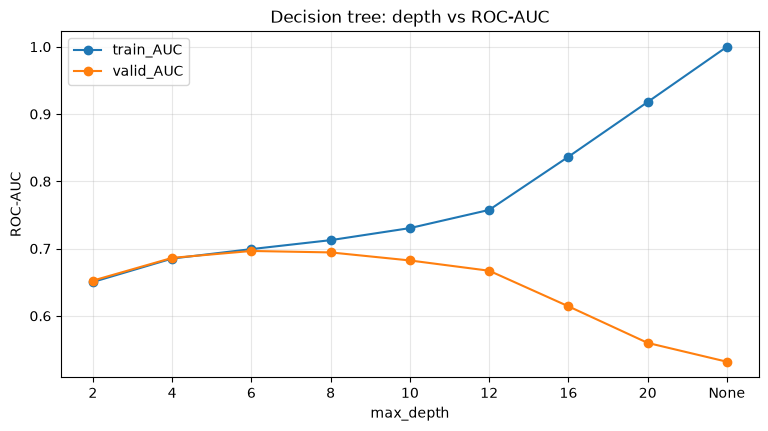

best depth on validation: 6


,train_AUC,valid_AUC,leaves
max_depth,,,
2,0.650,0.652,4
4,0.685,0.686,16
6,0.699,0.696,64
8,0.713,0.694,232
10,0.730,0.682,628
12,0.757,0.667,1416
16,0.837,0.614,4341
20,0.918,0.560,8518
None,1.000,0.532,19406


In [4]:
pre = prep().fit(X)
Xt, Xvt = pre.transform(X), pre.transform(Xv)
rows = []
for d in [2, 4, 6, 8, 10, 12, 16, 20, None]:
    t = DecisionTreeClassifier(max_depth=d, random_state=RNG).fit(Xt, tr.churned_6m)
    rows.append((str(d), roc_auc_score(tr.churned_6m, t.predict_proba(Xt)[:, 1]),
                 roc_auc_score(va.churned_6m, t.predict_proba(Xvt)[:, 1]), t.get_n_leaves()))
vc = pd.DataFrame(rows, columns=["max_depth", "train_AUC", "valid_AUC", "leaves"]).set_index("max_depth")
vc[["train_AUC", "valid_AUC"]].plot(marker="o", title="Decision tree: depth vs ROC-AUC"); plt.ylabel("ROC-AUC"); plt.show()
print("best depth on validation:", vc.valid_AUC.idxmax()); vc.round(3)

> **Think like a practitioner.** The forest uses trees grown much deeper than 8. Why does averaging 300 over-fitted trees not over-fit?

## Step 4 · Gains, lift and the call list

**Why this matters.** A **cumulative-gains** chart answers the campaign question directly: *if we call the top x% by score, what share of all churners do we reach?* **Lift** = that share ÷ x. Decile tables are how retention and collections teams consume models.

,customers,churners,churn_rate,lift,cum_capture
decile,,,,,
1,5000,1531,0.306,2.557,0.256
2,5000,1022,0.204,1.707,0.426
3,5000,817,0.163,1.364,0.563
4,5000,662,0.132,1.106,0.673
5,5000,527,0.105,0.880,0.761
6,5000,440,0.088,0.735,0.835
7,5000,394,0.079,0.658,0.901
8,5000,294,0.059,0.491,0.950
9,5000,194,0.039,0.324,0.982


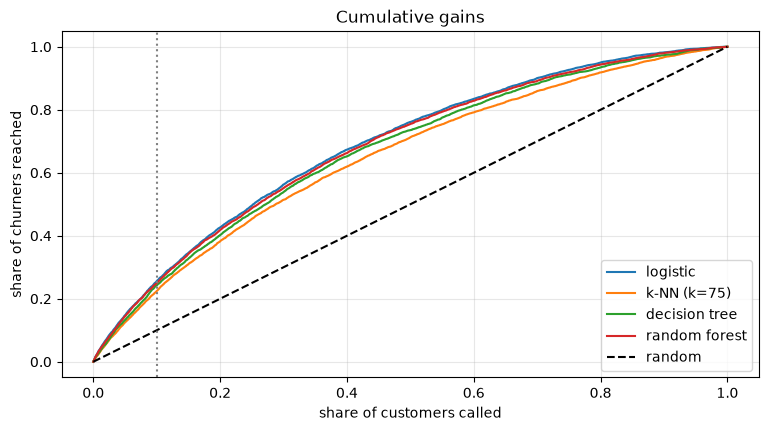

In [5]:
champ = board.index[0]
dec = pd.DataFrame({"y": va.churned_6m.to_numpy(), "p": P[champ]})
dec["decile"] = pd.qcut(dec.p.rank(method="first", ascending=False), 10, labels=range(1, 11))
table = dec.groupby("decile", observed=True).agg(customers=("y", "size"), churners=("y", "sum"), churn_rate=("y", "mean"))
table["lift"] = table.churn_rate / dec.y.mean()
table["cum_capture"] = table.churners.cumsum() / dec.y.sum()
display(table.round(3))
for name, p in P.items():
    order = np.argsort(-p); cum = np.cumsum(va.churned_6m.to_numpy()[order]) / va.churned_6m.sum()
    plt.plot(np.arange(1, len(p) + 1) / len(p), cum, label=name)
plt.plot([0, 1], [0, 1], "k--", label="random"); plt.axvline(0.10, color="grey", ls=":")
plt.xlabel("share of customers called"); plt.ylabel("share of churners reached"); plt.legend(); plt.title("Cumulative gains"); plt.show()

## Step 5 · Target by expected value, not by rank alone

**Why this matters.** Calling a customer costs AED 25 and a fee waiver AED 150 if accepted; ≈ 30% of would-be churners are saved, and a saved customer is worth ≈ 2% of their balance per year plus AED 400 product margin. **Expected value** = P(churn) × 0.30 × value − cost. Ranking by EV contacts high-value customers with moderate risk ahead of low-value customers with high risk.

In [6]:
v = va.assign(p=P[champ], value=0.02 * np.expm1(va.log_balance) + 400)
v["ev"] = v.p * 0.30 * v.value - (25 + v.p * 0.30 * 150)
n10 = int(0.10 * len(v))
policies = {"top 10% by P(churn)": v.nlargest(n10, "p"), "top 10% by EV": v.nlargest(n10, "ev"), "all with EV > 0": v[v.ev > 0]}
pd.DataFrame({k: {"called": len(s), "churners_reached": int(s.churned_6m.sum()), "expected_value_AED": s.ev.sum()}
              for k, s in policies.items()}).T.round(0)

,called,churners_reached,expected_value_AED
top 10% by P(churn),5000.0,1531.0,139832.0
top 10% by EV,5000.0,992.0,328824.0
all with EV > 0,16881.0,3107.0,444788.0


> **Think like a practitioner.** EV targeting favours wealthy customers. Is that acceptable for a retention campaign? Would it be for a *hardship* programme?

## Step 6 · Trees for regression — and why they cannot extrapolate

**Why this matters.** Trees also **regress**: each leaf predicts the mean of its training rows. That makes them flexible (no need for log transforms or splines) but **piecewise constant**: they can never predict outside the range seen in training. The Day 2 AVM was tested *out-of-time* on 2025 valuations, when prices kept rising. Can trees beat it?

In [7]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OrdinalEncoder
val = pd.read_csv(DATA / "property_valuations.csv", parse_dates=["valuation_date"])
ratio = (val.valuation_aed / val.size_sqft) / (val.valuation_aed / val.size_sqft).groupby([val.community, val.property_type]).transform("median")
val = val[ratio.between(0.25, 4)].copy()
val["months_since_2018"] = (val.valuation_date - pd.Timestamp("2018-01-01")).dt.days / 30.44
VC = ["emirate", "community", "property_type", "view"]
VN = ["bedrooms", "size_sqft", "building_age_years", "floor", "furnished", "private_pool", "parking_spaces",
      "distance_to_metro_km", "service_charge_aed_sqft", "off_plan", "months_since_2018"]
enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
past, fut = val[val.valuation_date < "2025-01-01"], val[val.valuation_date >= "2025-01-01"]
Xp = np.c_[past[VN], enc.fit_transform(past[VC])]; Xf = np.c_[fut[VN], enc.transform(fut[VC])]
oot = lambda pred: np.mean(np.abs(np.exp(pred) / fut.valuation_aed - 1))
res = {f"tree depth {d}": oot(DecisionTreeRegressor(max_depth=d, min_samples_leaf=20, random_state=RNG).fit(Xp, np.log(past.valuation_aed)).predict(Xf))
       for d in [6, 12, 20]}
rf_reg = RandomForestRegressor(n_estimators=150, min_samples_leaf=3, max_features=0.6, max_samples=0.5, n_jobs=-1, random_state=RNG)
p_rf = rf_reg.fit(Xp, np.log(past.valuation_aed)).predict(Xf)
res["random forest"] = oot(p_rf)
res["Day 2 linear AVM (L2.1)"] = json.loads((CKPT / "valuation_metrics.json").read_text())["oot_2025_mape"]
display(pd.Series(res, name="2025 out-of-time MAPE").round(4).to_frame())
print(f"forest median bias on 2025: {np.median(np.exp(p_rf) / fut.valuation_aed - 1):+.1%}")

,2025 out-of-time MAPE
tree depth 6,0.2797
tree depth 12,0.1361
tree depth 20,0.1266
random forest,0.1075
Day 2 linear AVM (L2.1),0.0975


forest median bias on 2025: -3.0%


> **Think like a practitioner.** How could you keep the forest but fix the trend problem? (Hint: model price *relative* to a market index, or combine linear + tree.)

## Step 7 · Explain, test once, save the champion

**Why this matters.** Retention managers will ask *why* a customer is on the list. **Permutation importance** on validation shows which features the champion actually relies on. Then the test set — untouched so far — gives the number we report, and the scores are saved for the Day 4 neural challenger and the Day 5 capstone.

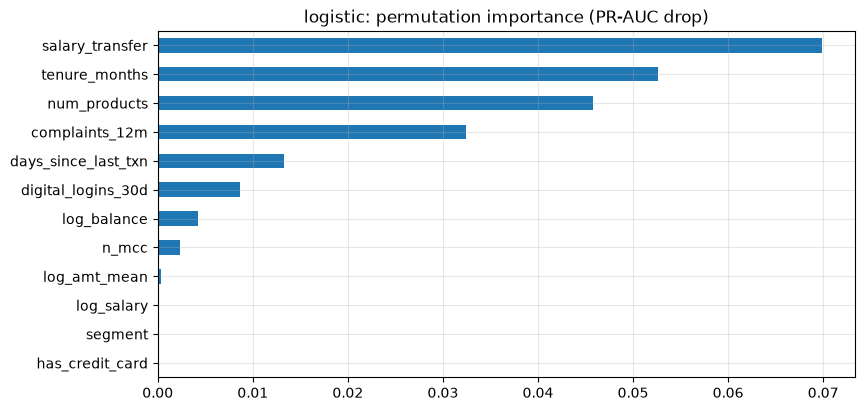

TEST logistic {'ROC_AUC': 0.709, 'PR_AUC': 0.251, 'capture@10%': 0.258}


saved churn_model.joblib and churn_scores.parquet


In [8]:
import joblib
from sklearn.inspection import permutation_importance
m = models[champ]
vs = va.sample(15_000, random_state=RNG)
pi = permutation_importance(m, vs[NUM + CAT], vs.churned_6m, scoring="average_precision", n_repeats=3, random_state=RNG, n_jobs=-1)
pd.Series(pi.importances_mean, index=NUM + CAT).sort_values().tail(12).plot.barh(title=f"{champ}: permutation importance (PR-AUC drop)"); plt.show()
p_te = m.predict_proba(te[NUM + CAT])[:, 1]
test = {"ROC_AUC": roc_auc_score(te.churned_6m, p_te), "PR_AUC": average_precision_score(te.churned_6m, p_te), "capture@10%": top_capture(te.churned_6m, p_te)}
print("TEST", champ, {k: round(v, 3) for k, v in test.items()})
all_p = m.predict_proba(df[NUM + CAT])[:, 1]
split = pd.Series("train", index=df.index); split[va.index] = "valid"; split[te.index] = "test"
scores = pd.DataFrame({"customer_id": df.customer_id, "p_churn": all_p, "split": split,
                       "decile": pd.qcut(pd.Series(all_p).rank(method="first", ascending=False), 10, labels=range(1, 11)).astype(int).to_numpy()})
scores.to_parquet(CKPT / "churn_scores.parquet", index=False)
joblib.dump({"model": m, "name": champ, "features": NUM + CAT, "test": test, "valid": board.loc[champ].to_dict(),
             "split_ids": {s: df.customer_id[split == s].tolist() for s in ["train", "valid", "test"]}}, CKPT / "churn_model.joblib", compress=3)
print("saved churn_model.joblib and churn_scores.parquet")

## ✅ Lab complete
Retention has a ranked, value-aware call list and Mortgage knows the limits of trees. **Tomorrow:** can SVMs and neural networks do better?